In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('state-groundwater-boards-changes-in-depth-to-water-level.csv')

In [5]:
df.shape

(358558, 17)

In [6]:
df.columns

Index(['id', 'date', 'state_name', 'state_code', 'district_name',
       'district_code', 'station_name', 'latitude', 'longitude', 'basin',
       'sub_basin', 'source', 'currentlevel', 'level_diff', 'Unnamed: 14',
       'Unnamed: 15', 'Unnamed: 16'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 358558 entries, 0 to 358557
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   id             358558 non-null  int64  
 1   date           358558 non-null  object 
 2   state_name     358555 non-null  object 
 3   state_code     358555 non-null  float64
 4   district_name  358555 non-null  object 
 5   district_code  358555 non-null  float64
 6   station_name   358558 non-null  object 
 7   latitude       358558 non-null  float64
 8   longitude      358558 non-null  float64
 9   basin          342716 non-null  object 
 10  sub_basin      342716 non-null  object 
 11  source         358558 non-null  object 
 12  currentlevel   358558 non-null  float64
 13  level_diff     358558 non-null  float64
 14  Unnamed: 14    0 non-null       float64
 15  Unnamed: 15    0 non-null       float64
 16  Unnamed: 16    12 non-null      object 
dtypes: float64(8), int64(1), obje

In [8]:
df.isnull().sum()

id                    0
date                  0
state_name            3
state_code            3
district_name         3
district_code         3
station_name          0
latitude              0
longitude             0
basin             15842
sub_basin         15842
source                0
currentlevel          0
level_diff            0
Unnamed: 14      358558
Unnamed: 15      358558
Unnamed: 16      358546
dtype: int64

In [9]:
df['state_name'].value_counts()

state_name
Uttar Pradesh    127126
Rajasthan         70309
Telangana         59129
Kerala            47156
Odisha            23476
Tamil Nadu        16808
Chhattisgarh      13046
Punjab             1489
Meghalaya            13
Assam                 3
Name: count, dtype: int64

In [10]:
up_df = df[df["state_name"] == "Uttar Pradesh"].copy()
up_df.head(3)

,id,date,state_name,state_code,district_name,district_code,station_name,latitude,longitude,basin,sub_basin,source,currentlevel,level_diff,Unnamed: 14,Unnamed: 15,Unnamed: 16
41773,41773,3/24/2019,Uttar Pradesh,9.0,Firozabad,143.0,"UP_Firozabad, Narkhi, P.S. Asan",27.25183,78.37578,Ganga,Yamuna Lower,Uttar Pradesh GW,32.64,32.29,NaN,NaN,NaN
41774,41774,3/25/2019,Uttar Pradesh,9.0,Firozabad,143.0,"UP_Firozabad, Narkhi, P.S. Asan",27.25183,78.37578,Ganga,Yamuna Lower,Uttar Pradesh GW,32.65,0.01,NaN,NaN,NaN
41775,41775,3/27/2019,Uttar Pradesh,9.0,Firozabad,143.0,"UP_Firozabad, Narkhi, P.S. Asan",27.25183,78.37578,Ganga,Yamuna Lower,Uttar Pradesh GW,32.63,-0.02,NaN,NaN,NaN


In [11]:
up_df.isnull().sum()

id                    0
date                  0
state_name            0
state_code            0
district_name         0
district_code         0
station_name          0
latitude              0
longitude             0
basin                 0
sub_basin             0
source                0
currentlevel          0
level_diff            0
Unnamed: 14      127126
Unnamed: 15      127126
Unnamed: 16      127126
dtype: int64

In [12]:
up_df.tail()

,id,date,state_name,state_code,district_name,district_code,station_name,latitude,longitude,basin,sub_basin,source,currentlevel,level_diff,Unnamed: 14,Unnamed: 15,Unnamed: 16
168894,168894,4/25/2019,Uttar Pradesh,9.0,Etah,138.0,"UP_Etah, Jalesar, Canal Office Jalesar",27.48172,78.31639,Ganga,Yamuna Lower,Uttar Pradesh GW,16.88,-0.01,NaN,NaN,NaN
168895,168895,4/27/2019,Uttar Pradesh,9.0,Etah,138.0,"UP_Etah, Jalesar, Canal Office Jalesar",27.48172,78.31639,Ganga,Yamuna Lower,Uttar Pradesh GW,16.89,0.01,NaN,NaN,NaN
168896,168896,4/28/2019,Uttar Pradesh,9.0,Etah,138.0,"UP_Etah, Jalesar, Canal Office Jalesar",27.48172,78.31639,Ganga,Yamuna Lower,Uttar Pradesh GW,16.88,-0.01,NaN,NaN,NaN
168897,168897,4/30/2019,Uttar Pradesh,9.0,Etah,138.0,"UP_Etah, Jalesar, Canal Office Jalesar",27.48172,78.31639,Ganga,Yamuna Lower,Uttar Pradesh GW,16.89,0.01,NaN,NaN,NaN
168898,168898,5/17/2019,Uttar Pradesh,9.0,Etah,138.0,"UP_Etah, Jalesar, Canal Office Jalesar",27.48172,78.31639,Ganga,Yamuna Lower,Uttar Pradesh GW,16.90,0.01,NaN,NaN,NaN


In [13]:
up_df['date'] = pd.to_datetime(up_df['date'], errors='coerce')
print("Date Range:", up_df['date'].min().date(), "to", up_df['date'].max().date())

Date Range: 2013-06-05 to 2022-05-25


In [14]:
print("Water Level status:\n", up_df['currentlevel'].describe())

Water Level status:
 count    127126.000000
mean         26.175622
std         176.378467
min           0.000000
25%          11.940000
50%          19.440000
75%          29.070000
max       11553.810000
Name: currentlevel, dtype: float64


In [15]:
print("Unique UP districts:\n", up_df['district_name'].nunique())

Unique UP districts:
 21


In [16]:
up_df['district_name'].value_counts()

district_name
Lucknow          24652
Agra             19152
Kanpur Nagar     13952
Mainpuri          9661
Firozabad         9292
Rae Bareli        8239
Unnao             7197
Farrukhabad       6507
Aligarh           6121
Hathras           5406
Kannauj           4770
Etah              3199
Kasganj           3015
Etawah            2313
Mathura           2313
Hardoi             436
Sitapur            403
Ghaziabad          168
Amroha             112
Baghpat            110
Muzaffarnagar      108
Name: count, dtype: int64

#VISUALIZATION

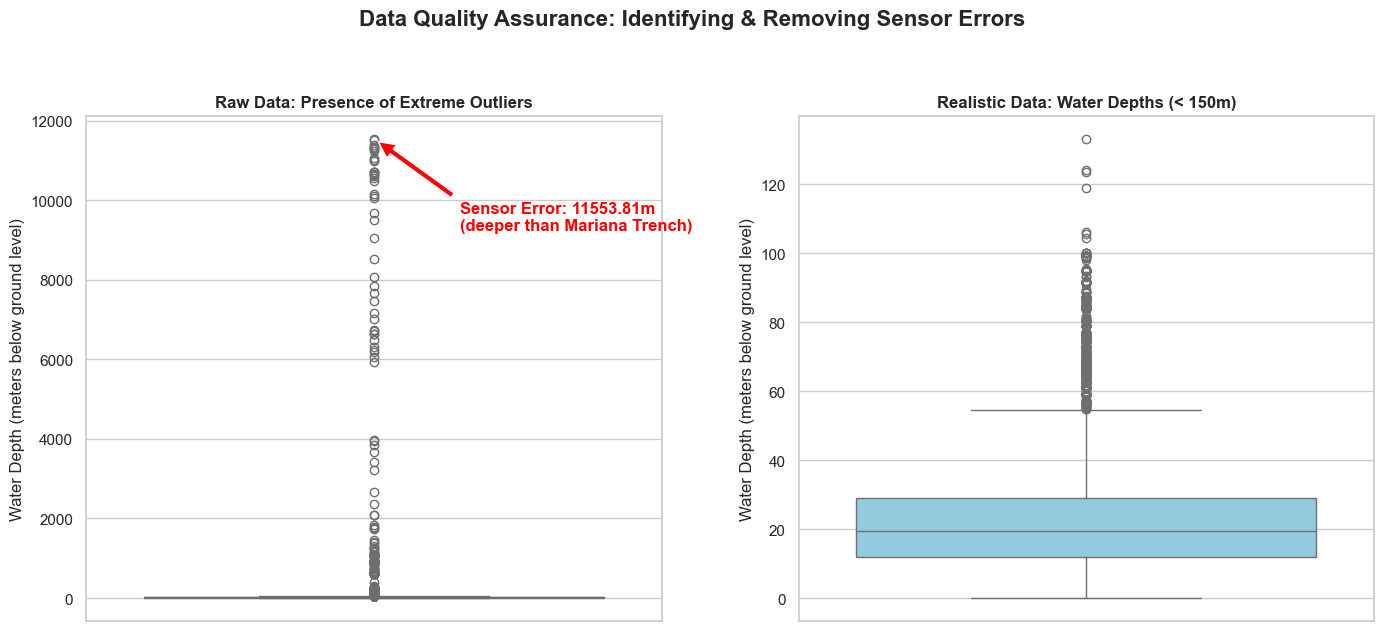

In [17]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(y=up_df['currentlevel'], ax=axes[0], color='lightcoral')
axes[0].set_title('Raw Data: Presence of Extreme Outliers', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Water Depth (meters below ground level)')

# Add an annotation arrow pointing to the massive error
max_val = up_df['currentlevel'].max()
axes[0].annotate(f'Sensor Error: {max_val}m\n(deeper than Mariana Trench)', 
                 xy=(0, max_val), xytext=(0.15, max_val * 0.8),
                 arrowprops=dict(facecolor='red', shrink=0.05),
                 color='red', fontweight='bold')

realistic_data = up_df[up_df['currentlevel'] < 150]['currentlevel']

sns.boxplot(y=realistic_data, ax=axes[1], color='skyblue')
axes[1].set_title('Realistic Data: Water Depths (< 150m)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Water Depth (meters below ground level)')

# Add an overarching title for the report
plt.suptitle('Data Quality Assurance: Identifying & Removing Sensor Errors', 
             fontsize=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

#Cleanning the data

In [18]:
columns_to_drop = [
    'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 
    'id', 'state_code', 'district_code', 'station_name', 
    'basin', 'sub_basin', 'source', 'level_diff'
]
up_clean = up_df.drop(columns=columns_to_drop).copy()

In [19]:
up_clean.shape

(127126, 6)

In [20]:
up_clean.columns

Index(['date', 'state_name', 'district_name', 'latitude', 'longitude',
       'currentlevel'],
      dtype='object')

In [21]:
up_clean['currentlevel'].max() #Deeper than Mariana Trench

np.float64(11553.81)

In [22]:
#Filtering outliers because GW level over 150m is likely typo.
up_clean = up_clean[(up_clean['currentlevel'] >= 0) & (up_clean['currentlevel'] < 150)]


In [23]:
#Creating New columns for Year and months
up_clean['Year'] = up_clean['date'].dt.year
up_clean['Month'] = up_clean['date'].dt.month

In [24]:
print("Cleaned Dataset Shape:", up_clean.shape)
print("Realistic Max Water Depth:", up_clean['currentlevel'].max())
up_clean.head(3)

Cleaned Dataset Shape: (126896, 8)
Realistic Max Water Depth: 133.21


,date,state_name,district_name,latitude,longitude,currentlevel,Year,Month
41773,2019-03-24,Uttar Pradesh,Firozabad,27.25183,78.37578,32.64,2019,3
41774,2019-03-25,Uttar Pradesh,Firozabad,27.25183,78.37578,32.65,2019,3
41775,2019-03-27,Uttar Pradesh,Firozabad,27.25183,78.37578,32.63,2019,3


#DATA AGGREGATION - We created 72 distinct "District-Year" data points that are ready to be matched 1-to-1 with crop yield data.

In [25]:
#Group the data by District and Year, calculating the mean water level
annual_gw = up_clean.groupby(['district_name', 'Year'])['currentlevel'].mean().reset_index()

#Rename the column to reflect that it is now a yearly average
annual_gw.rename(columns={'currentlevel': 'avg_water_depth'}, inplace=True)



In [26]:
annual_gw.head(3)

,district_name,Year,avg_water_depth
0,Agra,2015,23.310000
1,Agra,2018,38.518889
2,Agra,2019,31.184806


In [27]:
annual_gw.to_csv('UP_Annual_Groundwater_Ready.csv', index=False)

In [28]:
print("Baghpat Annual Averages:")
print(annual_gw[annual_gw['district_name'] == 'Baghpat'].head())

Baghpat Annual Averages:
   district_name  Year  avg_water_depth
12       Baghpat  2022        16.693727


In [29]:
annual_gw['district_name'].value_counts()

district_name
Aligarh          6
Agra             5
Mainpuri         5
Mathura          5
Kanpur Nagar     5
Lucknow          5
Rae Bareli       4
Etah             4
Farrukhabad      4
Firozabad        4
Kannauj          3
Kasganj          3
Etawah           3
Unnao            3
Sitapur          3
Hardoi           3
Hathras          3
Baghpat          1
Amroha           1
Ghaziabad        1
Muzaffarnagar    1
Name: count, dtype: int64

In [30]:
#What happened to rest of the data -> it was compressed. If the raw data had 300 individual daily well readings for Agra in 2019,
#the groupby function mathematically averaged all 300 of them into a single definitive number (31.18m) .
#representing Agra's water table for that entire year.

In [31]:
df_crop = pd.read_csv('APY.csv', low_memory=False)
df_crop.columns

FileNotFoundError: [Errno 2] No such file or directory: 'APY.csv'

In [ ]:
df_crop.columns = df_crop.columns.str.strip()
df_crop.columns

Index(['State', 'District', 'Crop', 'Crop_Year', 'Season', 'Area',
       'Production', 'Yield'],
      dtype='object')

In [ ]:
up_crop = df_crop[(df_crop['State'] == 'Uttar Pradesh') & 
                  (df_crop['Crop_Year'] >= 2013) & 
                  (df_crop['Crop_Year'] <= 2019)].copy()

In [ ]:
print("\nTotal Unique Crops in UP:", up_crop['Crop'].nunique())


Total Unique Crops in UP: 33


In [ ]:
print("\nMissing Values in UP:\n", up_crop.isnull().sum())


Missing Values in UP:
 State          0
District       0
Crop           0
Crop_Year      0
Season         0
Area           0
Production    39
Yield          0
dtype: int64


In [ ]:
up_crop['Crop'].value_counts()

Crop
Maize                    1265
Onion                    1012
Urad                      952
Moong(Green Gram)         867
Rice                      682
Potato                    525
Rapeseed &Mustard         525
Wheat                     525
Sugarcane                 525
Masoor                    520
Peas & beans (Pulses)     517
Barley                    514
Arhar/Tur                 502
Dry chillies              485
Sesamum                   484
Gram                      466
Sweet potato              453
Coriander                 446
Bajra                     441
Garlic                    433
Groundnut                 413
Guar seed                 395
Jowar                     395
Banana                    318
Linseed                   280
Sunflower                 222
Turmeric                  219
Sannhamp                  211
Tobacco                   208
Small millets             187
Soyabean                   88
Cotton(lint)               83
Ginger                     46
Name:

In [ ]:
target_crops = ['Sugarcane', 'Rice', 'Wheat', 'Bajra', 
    'Maize', 'Potato', 'Rapeseed &Mustard']

In [ ]:
up_crop_filtered = up_crop[up_crop['Crop'].isin(target_crops)].copy()

In [ ]:
print("Filtered Crop Data Shape:", up_crop_filtered.shape)
print("\nMissing Values:\n", up_crop_filtered.isnull().sum())
print("\nUnique Crops Included:\n", up_crop_filtered['Crop'].unique())
up_crop_filtered.head(3)

Filtered Crop Data Shape: (4488, 8)

Missing Values:
 State         0
District      0
Crop          0
Crop_Year     0
Season        0
Area          0
Production    0
Yield         0
dtype: int64

Unique Crops Included:
 ['Bajra' 'Maize' 'Potato' 'Rapeseed &Mustard' 'Rice' 'Sugarcane' 'Wheat']


,State,District,Crop,Crop_Year,Season,Area,Production,Yield
282718,Uttar Pradesh,AGRA,Bajra,2013,Kharif,118294.0,284151.0,2.40
282719,Uttar Pradesh,AGRA,Bajra,2014,Kharif,118146.0,246736.0,2.09
282720,Uttar Pradesh,AGRA,Bajra,2015,Kharif,129352.0,245947.0,1.90


In [ ]:
#Capitalize District names in both datasets to ensure a perfect match
annual_gw['district_name'] = annual_gw['district_name'].str.upper().str.strip()
up_crop_filtered['District'] = up_crop_filtered['District'].str.upper().str.strip()

In [ ]:
# Rename Crop_Year to Year so the column names match exactly
up_crop_filtered.rename(columns={'Crop_Year': 'Year'}, inplace=True)

In [ ]:
#Pivot the crop data: 
#This turns crops into columns (e.g., creating a 'Sugarcane_Area' column)
crop_pivot = up_crop_filtered.pivot_table(
    index=['District', 'Year'], 
    columns='Crop', 
    values='Area', 
    aggfunc='sum'
).reset_index()

In [ ]:
# 4. Fill any missing crop areas with 0 (e.g., if a district didn't grow Bajra that year)
crop_pivot = crop_pivot.fillna(0)

In [ ]:
crop_pivot.head()

Crop,District,Year,Bajra,Maize,Potato,Rapeseed &Mustard,Rice,Sugarcane,Wheat
0,AGRA,2013,118294.0,172.0,60110.0,53142.0,8691.0,255.0,132340.0
1,AGRA,2014,118146.0,344.0,67228.0,45613.0,10164.0,145.0,136036.0
2,AGRA,2015,129352.0,222.0,77606.0,38621.0,9401.0,224.0,120903.0
3,AGRA,2016,115536.0,883.0,67006.0,52027.0,4872.0,153.0,128553.0
4,AGRA,2017,122628.0,164.0,57879.0,53836.0,5252.0,256.0,137141.0


In [ ]:
#THE ULTIMATE MERGE (Inner Join)
final_master_df = pd.merge(
    annual_gw, 
    crop_pivot, 
    left_on=['district_name', 'Year'], 
    right_on=['District', 'Year'], 
    how='inner'
)

In [ ]:
final_master_df.head(3)

,district_name,Year,avg_water_depth,District,Bajra,Maize,Potato,Rapeseed &Mustard,Rice,Sugarcane,Wheat
0,AGRA,2015,23.310000,AGRA,129352.0,222.0,77606.0,38621.0,9401.0,224.0,120903.0
1,AGRA,2018,38.518889,AGRA,113877.0,242.0,56630.0,61193.0,5432.0,205.0,132369.0
2,AGRA,2019,31.184806,AGRA,118486.0,172.0,57010.0,54866.0,5330.0,213.0,137283.0


In [ ]:
# 6. Drop the redundant 'District' column after merging
final_master_df.drop(columns=['District'], inplace=True)

In [ ]:
# Save the final dataset for the Machine Learning phase!
final_master_df.to_csv('Project_Master_Dataset.csv', index=False)

In [ ]:
print("Final Merged Dataset Shape:", final_master_df.shape)
final_master_df.head(3)

Final Merged Dataset Shape: (34, 10)


,district_name,Year,avg_water_depth,Bajra,Maize,Potato,Rapeseed &Mustard,Rice,Sugarcane,Wheat
0,AGRA,2015,23.310000,129352.0,222.0,77606.0,38621.0,9401.0,224.0,120903.0
1,AGRA,2018,38.518889,113877.0,242.0,56630.0,61193.0,5432.0,205.0,132369.0
2,AGRA,2019,31.184806,118486.0,172.0,57010.0,54866.0,5330.0,213.0,137283.0


#calculate the Pearson correlation and plots

In [ ]:
#Selecting only the numeric columns to calculate correlation
numeric_cols = ['avg_water_depth', 'Bajra', 'Maize', 'Potato', 'Rapeseed &Mustard', 'Rice', 'Sugarcane', 'Wheat']
corr = final_master_df[numeric_cols].corr()

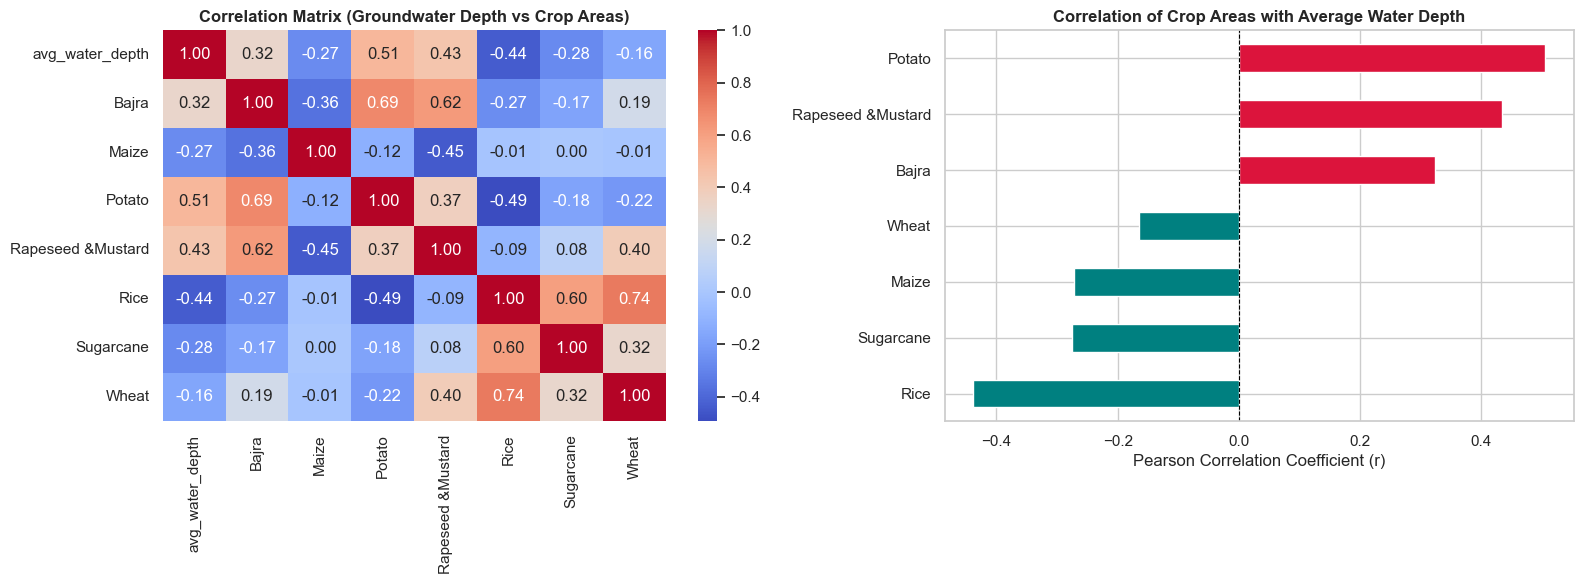

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#Subplot 1: The Full Heatmap ---
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0], cbar=True)
axes[0].set_title('Correlation Matrix (Groundwater Depth vs Crop Areas)', fontsize=12, fontweight='bold')

#Subplot 2: The Target Variable Bar Chart ---
# Isolate the correlation with our target (water depth), drop itself (which is 1.0), and sort
water_corr = corr['avg_water_depth'].drop('avg_water_depth').sort_values()

# Color positive correlations red (crimson) and negative correlations blue/green (teal)
colors = ['crimson' if x > 0 else 'teal' for x in water_corr]

water_corr.plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Correlation of Crop Areas with Average Water Depth', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Pearson Correlation Coefficient (r)')
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--') # Adds a center line at 0

# 3. Adjust layout and display
plt.tight_layout()
plt.show()